Live deployment: **Add your actual public app URL here after deployment.**

# Heart Disease Prediction System
**Student:** Muhammad Awais  
**Registration No.:** FA24-BSE-076  
**Section:** BSE-A  
**Course:** Machine Learning Fundamentals (AIC354)

This notebook builds an end-to-end binary classifier using four input attributes from the UCI Cleveland Heart Disease dataset. The four inputs are `age`, `sex`, `trestbps`, and `chol`.

## 1. Import libraries

In [1]:
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from pathlib import Path

RANDOM_STATE = 42
DATA_PATH = Path("awais_heart_disease.csv")
MODEL_PATH = Path("awais_heart_model.pkl")


## 2. Load the dataset

In [2]:
heart_data = pd.read_csv(DATA_PATH)
print("Dataset shape:", heart_data.shape)
display(heart_data.head())
print("Columns:", heart_data.columns.tolist())

Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0.0


Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


The dataset is the Cleveland subset of the UCI Heart Disease dataset. The source has 14 columns, including `num`, the original disease indicator. The CSV included here has explicit column names so it can be loaded directly.

## 3. Understand and preprocess the data

In [3]:
heart_data.info()
display(heart_data.isna().sum().to_frame("Missing values"))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    float64
dtypes: float64(14)
memory usage: 33.3 KB


,Missing values
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [4]:
features = ["age", "sex", "trestbps", "chol"]
required = features + ["num"]
model_data = heart_data[required].copy()
for column in required:
    model_data[column] = pd.to_numeric(model_data[column], errors="coerce")
rows_before = len(model_data)
model_data = model_data.dropna(subset=required).copy()
model_data["HeartDisease"] = (model_data["num"] > 0).astype(int)
model_data = model_data[features + ["HeartDisease"]]
print("Rows before selected-column cleaning:", rows_before)
print("Rows used:", len(model_data))
print("Missing values after cleaning:", int(model_data.isna().sum().sum()))
display(model_data.head())

Rows before selected-column cleaning: 303
Rows used: 303
Missing values after cleaning: 0


,age,sex,trestbps,chol,HeartDisease
0,63.0,1.0,145.0,233.0,0
1,67.0,1.0,160.0,286.0,1
2,67.0,1.0,120.0,229.0,1
3,37.0,1.0,130.0,250.0,0
4,41.0,0.0,130.0,204.0,0


## 4. Exploratory data analysis (EDA)

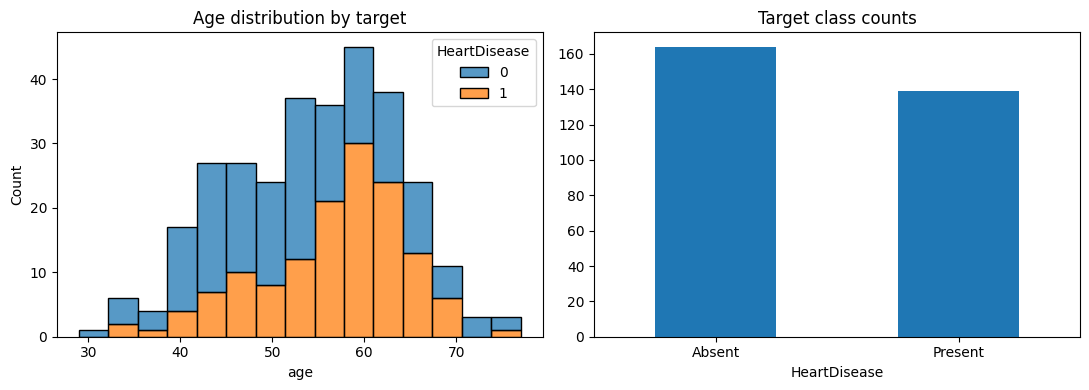

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=model_data, x="age", hue="HeartDisease", multiple="stack", bins=15, ax=axes[0])
axes[0].set_title("Age distribution by target")
model_data["HeartDisease"].value_counts().reindex([0, 1], fill_value=0).plot(kind="bar", ax=axes[1])
axes[1].set_title("Target class counts")
axes[1].set_xticks([0, 1], ["Absent", "Present"], rotation=0)
plt.tight_layout()
plt.show()

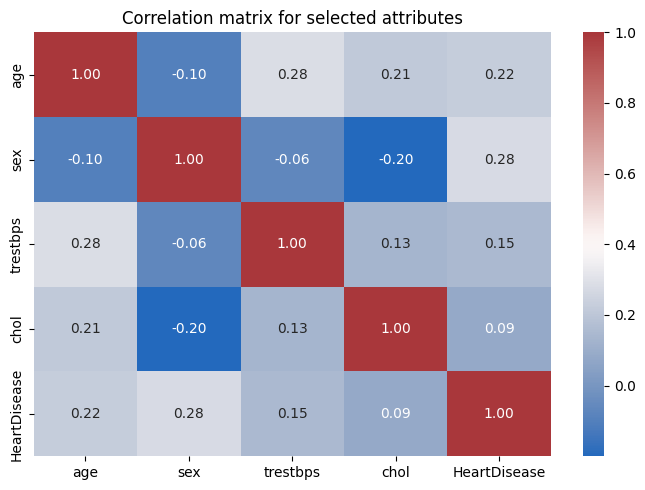

In [6]:
plt.figure(figsize=(7, 5))
sns.heatmap(model_data.corr(numeric_only=True), annot=True, cmap="vlag", fmt=".2f")
plt.title("Correlation matrix for selected attributes")
plt.tight_layout()
plt.show()

## 5. Select four inputs and define the target

In [7]:
X = model_data[features].astype(float)
y = model_data["HeartDisease"].astype(int)
print("Selected input attributes:", features)
print("Input matrix shape:", X.shape)
print("Target counts:")
display(y.value_counts().rename(index={0: "Absent", 1: "Present"}).to_frame("Count"))

Selected input attributes: ['age', 'sex', 'trestbps', 'chol']
Input matrix shape: (303, 4)
Target counts:


,Count
HeartDisease,
Absent,164
Present,139


The original `num` target is converted into two classes: `0` means disease absent; any value above `0` means disease present. Only the four selected attributes are used as model inputs.

## 6. Split data into training and testing sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 242
Testing rows: 61


## 7. Train the model

In [9]:
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)
)
model.fit(X_train, y_train)
print("Model training completed.")

Model training completed.


## 8. Evaluate the model

In [10]:
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print(f"Test accuracy: {accuracy:.2%}")
print(classification_report(y_test, predictions, target_names=["Disease absent", "Disease present"], zero_division=0))

Test accuracy: 65.57%
                 precision    recall  f1-score   support

 Disease absent       0.67      0.73      0.70        33
Disease present       0.64      0.57      0.60        28

       accuracy                           0.66        61
      macro avg       0.65      0.65      0.65        61
   weighted avg       0.65      0.66      0.65        61



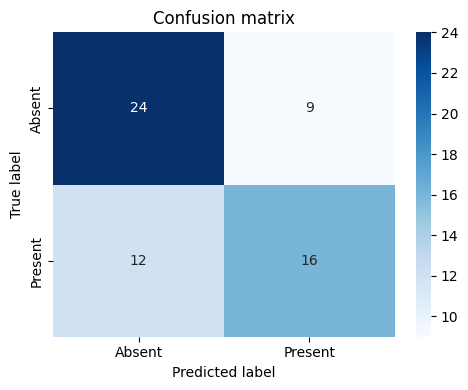

In [11]:
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Absent", "Present"], yticklabels=["Absent", "Present"])
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion matrix")
plt.tight_layout()
plt.savefig("confusion_matrix_awais.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Save the trained model and prediction results

In [12]:
with open(MODEL_PATH, "wb") as file:
    pickle.dump(model, file)

prediction_results = X_test.copy()
prediction_results["Actual"] = y_test.values
prediction_results["Predicted"] = predictions
prediction_results.to_csv("awais_test_predictions.csv", index=False)
results = {
    "student": "Muhammad Awais",
    "registration_no": "FA24-BSE-076",
    "section": "BSE-A",
    "features": features,
    "rows_used": int(len(model_data)),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "accuracy": float(accuracy),
    "confusion_matrix": cm.tolist(),
    "model": "StandardScaler + LogisticRegression"
}
Path("awais_results.json").write_text(json.dumps(results, indent=2))
print("Saved model:", MODEL_PATH)
print("Saved predictions: awais_test_predictions.csv")
print("Saved results: awais_results.json")

Saved model: awais_heart_model.pkl
Saved predictions: awais_test_predictions.csv
Saved results: awais_results.json


## 10. Application: predict for a new example

In [13]:
example_patient = pd.DataFrame([{
    "age": 54,
    "sex": 1,
    "trestbps": 130,
    "chol": 240
}])
example_prediction = int(model.predict(example_patient)[0])
print("Input example:")
display(example_patient)
print("Predicted class:", "Disease present" if example_prediction == 1 else "Disease absent")

Input example:


,age,sex,trestbps,chol
0,54,1,130,240


Predicted class: Disease present


## 11. Feedback and limitations

The test-set evaluation is used to review the model's behavior and identify possible errors. No external user feedback has been collected as part of this project yet. If the instructor requires human feedback, ask a real user to try the app and record their genuine comments.

The model is a coursework demonstration, not a medical diagnostic system. Its performance depends on a small historical dataset and should not be used for clinical decisions.

## 12. Conclusion

In [14]:
print(f"Test accuracy: {accuracy:.2%}")
print("Training, testing, application, and test-result review completed.")

Test accuracy: 65.57%
Training, testing, application, and test-result review completed.
